# 0.0. IMPORTS

In [62]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import inflection

## 0.1. Helper Functions

## 0.2. Loading Data

In [2]:
df_sales_raw = pd.read_csv('data/train.csv', low_memory=False)
df_store_raw = pd.read_csv('data/store.csv', low_memory=False)

# 1.0. DESCRICAO DOS DADOS

In [3]:
# join à esquerda entre os dataframes df_sales_raw e df_store_raw usando a chave primária Store
df_raw = pd.merge(df_sales_raw, df_store_raw, how='left', on='Store')

In [4]:
# cópia do merge
df1 = df_raw.copy()

## 1.1. Rename Columns

In [5]:
# seleciona todas as colunas do dataframe df1 e armazena em cols_old
cols_old = df1.columns

# cria uma função lambda para transformar os nomes das colunas no formato snakecase
snakecase = lambda x: inflection.underscore(x)

# aplica essa função lambda em cima dos nomes das colunas antigas para realizar a transformação
cols_new = list(map(snakecase, cols_old))

# realiza a renomeação das colunas
df1.columns = cols_new

## 1.2. Data Dimensions

In [6]:
# exibe o número de linhas e colunas do dataframe
print(f'Number of Rows: {df1.shape[0]}')
print(f'Number of Cols: {df1.shape[1]}')

Number of Rows: 1017209
Number of Cols: 18


## 1.3. Data Types

In [7]:
# altera o tipo de dado da coluna date para o tipo data
df1['date'] = pd.to_datetime(df1['date'])

# exibe os tipos de dados de cada coluna do dataframe df1
df1.dtypes

store                                    int64
day_of_week                              int64
date                            datetime64[ns]
sales                                    int64
customers                                int64
open                                     int64
promo                                    int64
state_holiday                           object
school_holiday                           int64
store_type                              object
assortment                              object
competition_distance                   float64
competition_open_since_month           float64
competition_open_since_year            float64
promo2                                   int64
promo2_since_week                      float64
promo2_since_year                      float64
promo_interval                          object
dtype: object

## 1.4. Check NA

In [8]:
# lista a quantidade de NA por coluna do dataframe df1
df1.isna().sum()

store                                0
day_of_week                          0
date                                 0
sales                                0
customers                            0
open                                 0
promo                                0
state_holiday                        0
school_holiday                       0
store_type                           0
assortment                           0
competition_distance              2642
competition_open_since_month    323348
competition_open_since_year     323348
promo2                               0
promo2_since_week               508031
promo2_since_year               508031
promo_interval                  508031
dtype: int64

## 1.5. Fillout Na

In [9]:
df1['competition_distance'].max()

75860.0

In [10]:
# competition_distance 
df1['competition_distance'] = df1['competition_distance'].apply(lambda x: 200000.0 if math.isnan(x) else x)

# para tratar os valores ausentes em competition_distance seguiu-se a convenção de que se alguma observação de competition_distance é NA
# isso significa que a loja em questão não possui concorrência próxima, por isso, decidiu-se aplicar um valor maior que o máximo de quando se tinha
# valores ausentes

# competition_open_since_month 
df1['competition_open_since_month'] = df1.apply(lambda x: x['date'].month if math.isnan( x['competition_open_since_month'] ) else x['competition_open_since_month'], axis=1)

# para tratar os valores ausentes em competition_open_since_month, entrou-se no consenso de que se não houvesse um mês de início de concorrência com
# uma loja próxima, o mês a ser imputado seria extraído da coluna date

# competition_open_since_year    
df1['competition_open_since_year'] = df1.apply(lambda x: x['date'].year if math.isnan( x['competition_open_since_year'] ) else x['competition_open_since_year'], axis=1)

# para tratar os valores ausentes em competition_open_since_year, entrou-se no consenso de que se não houvesse um ano de início de concorrência com
# uma loja próxima, o ano a ser imputado seria extraído da coluna date

# promo2_since_week  
df1['promo2_since_week'] = df1.apply(lambda x: x['date'].week if math.isnan( x['promo2_since_week'] ) else x['promo2_since_week'], axis=1)

# para tratar os valores ausentes em promo2_since_week, entrou-se no consenso de que se não houvesse uma semana de início da campanha de promoções 2,
# seria imputada a semana correspondente extraída da coluna date

# promo2_since_year 
df1['promo2_since_year'] = df1.apply(lambda x: x['date'].year if math.isnan( x['promo2_since_year'] ) else x['promo2_since_year'], axis=1)

# para tratar os valores ausentes em promo2_since_year, entrou-se no consenso de que se não houvesse um ano de início da campanha de promoções 2,
# seria imputado o ano correspondente extraído da coluna date

# promo_interval

# dicionário auxiliar responsável por mapear número do mês em nome do mês
month_map = {
    1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Apr',
    5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug',
    9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}

# preencher todas as observações NA da coluna promo_interval com 0 
df1['promo_interval'] = df1['promo_interval'].fillna(0)

# extrair a informação numérica de mês da coluna date, mapear esse número para nome do mês e criar uma coluna month_map
df1['month_map'] = df1['date'].dt.month.map(month_map)

# verificar se o mês month_map está inserido em promo_interval, verificar se houve promo_interval de fato e criar uma coluna is_promo onde:
# 0 = não faz sentido que a loja esteve em promoção naquele mês
# 1 = faz sentido que a loja esteve em promoção naquele mês
df1['is_promo'] = df1[['promo_interval', 'month_map']].apply(
    lambda x: 0 if x['promo_interval'] == 0
    else 1 if x['month_map'] in x['promo_interval'].split(',')
    else 0,
    axis=1
)

In [12]:
# lista a quantidade de NA por coluna do dataframe df1 após o tratamento de NA
df1.isna().sum()

store                           0
day_of_week                     0
date                            0
sales                           0
customers                       0
open                            0
promo                           0
state_holiday                   0
school_holiday                  0
store_type                      0
assortment                      0
competition_distance            0
competition_open_since_month    0
competition_open_since_year     0
promo2                          0
promo2_since_week               0
promo2_since_year               0
promo_interval                  0
month_map                       0
is_promo                        0
dtype: int64

## 1.6. Change Types

In [14]:
df1['competition_open_since_month'] = df1['competition_open_since_month'].astype(int)
df1['competition_open_since_year'] = df1['competition_open_since_year'].astype(int)

df1['promo2_since_week'] = df1['promo2_since_week'].astype(int)
df1['promo2_since_year'] = df1['promo2_since_year'].astype(int)

## 1.7. Descriptive Statistical

In [21]:
# separar o dataframe em atributos numéricos e categóricos
num_attributes = df1.select_dtypes(include=['int64', 'float64'])
cat_attributes = df1.select_dtypes(exclude=['int64', 'float64', 'datetime64[ns]'])

## 1.7.1. Numerical Attributes

In [31]:
# Central Tendency - mean, median
ct1 = pd.DataFrame(num_attributes.apply(np.mean)).T
ct2 = pd.DataFrame(num_attributes.apply(np.median)).T

# Dispersion - std, min, max, range, skew, kurtosis
d1 = pd.DataFrame(num_attributes.apply(np.std)).T
d2 = pd.DataFrame(num_attributes.apply(min)).T
d3 = pd.DataFrame(num_attributes.apply(max)).T
d4 = pd.DataFrame(num_attributes.apply(lambda x: x.max() - x.min())).T
d5 = pd.DataFrame(num_attributes.apply(lambda x: x.skew())).T
d6 = pd.DataFrame(num_attributes.apply(lambda x: x.kurtosis())).T

# concatenate
m = pd.concat([d2, d3, d4, ct1, ct2, d1, d5, d6]).T.reset_index()
m.columns = ['attributes', 'min', 'max', 'range', 'mean', 'median', 'std', 'skew', 'kurtosis']

In [32]:
m

,attributes,min,max,range,mean,median,std,skew,kurtosis
0,store,1.0,1115.0,1114.0,558.429727,558.0,321.908493,-0.000955,-1.200524
1,day_of_week,1.0,7.0,6.0,3.998341,4.0,1.997390,0.001593,-1.246873
2,sales,0.0,41551.0,41551.0,5773.818972,5744.0,3849.924283,0.641460,1.778375
3,customers,0.0,7388.0,7388.0,633.145946,609.0,464.411506,1.598650,7.091773
4,open,0.0,1.0,1.0,0.830107,1.0,0.375539,-1.758045,1.090723
5,promo,0.0,1.0,1.0,0.381515,0.0,0.485758,0.487838,-1.762018
6,school_holiday,0.0,1.0,1.0,0.178647,0.0,0.383056,1.677842,0.815154
7,competition_distance,20.0,200000.0,199980.0,5935.442677,2330.0,12547.646829,10.242344,147.789712
8,competition_open_since_month,1.0,12.0,11.0,6.786849,7.0,3.311085,-0.042076,-1.232607
9,competition_open_since_year,1900.0,2015.0,115.0,2010.324840,2012.0,5.515591,-7.235657,124.071304


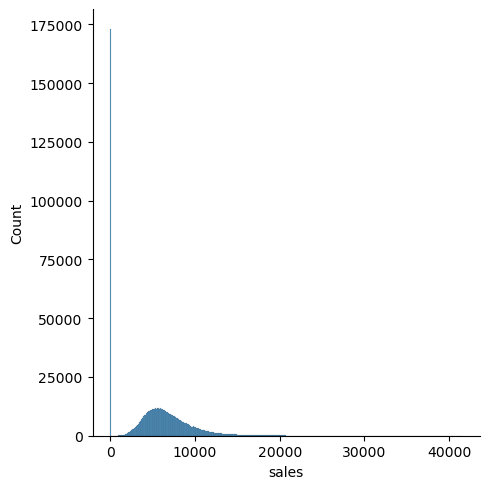

In [52]:
sns.displot(df1['sales']);

### 1.7.1. Observações:
<h4>skew</h4>
<ul>
    <li>skew muito positiva: gráfico mais deslocado para a esquerda</li>
    <li>skew muito negativa: gráfico mais deslocado para a direita</li>
</ul>
<h4>kurtosis</h4>
<ul>
    <li>kurtosis alta: maior densidade</li>
    <li>kurtosis baixa: menor densidade</li>
</ul>

## 1.7.2. Categorical Attributes

In [55]:
# quantidade de valores únicos por variável categórica
cat_attributes.apply(lambda x: x.unique().shape[0])

state_holiday      4
store_type         4
assortment         3
promo_interval     4
month_map         12
dtype: int64

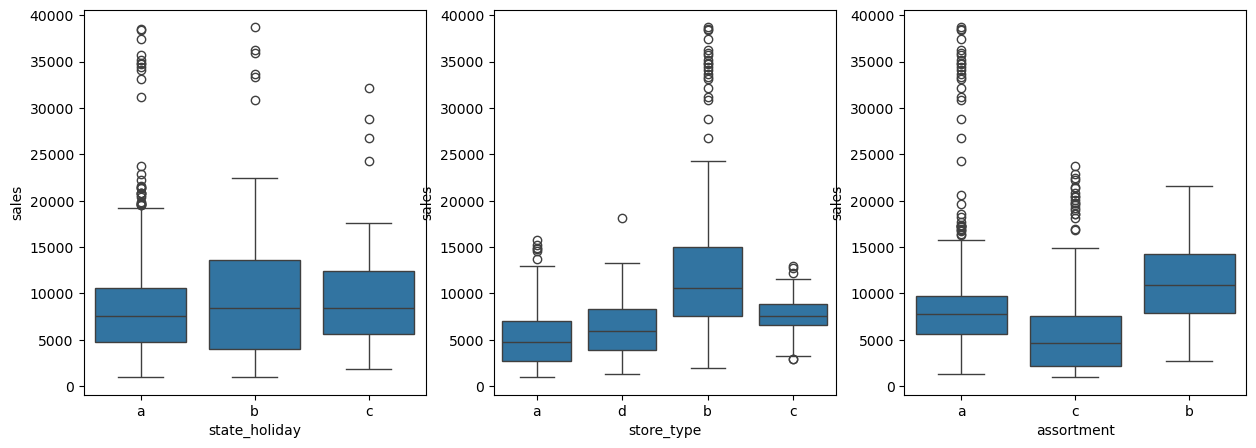

In [72]:
aux1 = df1[(df1['state_holiday'] != '0') & (df1['sales'] > 0)]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x='state_holiday', y='sales', data=aux1, ax=ax[0]);

sns.boxplot(x='store_type', y='sales', data=aux1, ax=ax[1]);

sns.boxplot(x='assortment', y='sales', data=aux1, ax=ax[2]);

# 1.1